# 第7讲 从症状到预测 机器学习基础与朴素贝叶斯
配合新版工作单七项任务。任务1与3运行A；任务4运行A2与C；任务5和6运行B；任务7固定方案后运行D。核心问题是怎样从数据学习模型并评价预测。测试默认关闭。

In [1]:
from pathlib import Path
import sys, json
sys.dont_write_bytecode = True
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
candidates = [Path.cwd(), Path.cwd().parent,
              Path.cwd()/'class2026/materials/7. Naive-Bayes']
BASE = next(p for p in candidates if (p/'scripts/lab_utils.py').exists())
sys.path.insert(0,str(BASE/'scripts'))
from lab_utils import *
REPO = next((p for p in [BASE,*BASE.parents] if (p/'.gitignore').exists()), BASE)
OUT = REPO/'.tmp/naive-bayes/student-results'
OUT.mkdir(parents=True,exist_ok=True)
FREEZE_CONFIRMED = False
OPEN_LOCKED_TEST = False
TRANSFER_FREEZE_CONFIRMED = False
OPEN_TRANSFER_TEST = False
train = pd.read_csv(BASE/'data/student/train.csv')
val = pd.read_csv(BASE/'data/student/validation.csv')
TARGET = 'bladder_inflammation'
print('模型输入:',FEATURES)


模型输入: ['fever_ge_38', 'nausea', 'lumbar_pain', 'urine_pushing', 'micturition_pain', 'burning_urethra']


## A 数据审计
对应任务1与3。观察训练表并记录数据划分；仅审计开发数据；完全重复比较去掉ID后的全部列，模式比较只取六输入。读取来源说明，并核对作者与构建目的。

In [2]:
for name, frame in [('train',train),('validation',val)]:
    print(name, 'n=',len(frame),'labels=',frame[TARGET].value_counts().to_dict(),
          'missing=',int(frame.isna().sum().sum()),
          'illegal bits=',int((~frame[FEATURES].isin([0,1])).sum().sum()),
          'extra duplicates=',int(frame.drop(columns='sample_id').duplicated().sum()),
          'unique profiles=',len(frame[FEATURES].drop_duplicates()))
assert not set(train.sample_id)&set(val.sample_id)
profiles_train = set(map(tuple,train[FEATURES].to_numpy()))
print('validation rows with profiles seen in train:',
      sum(tuple(x) in profiles_train for x in val[FEATURES].to_numpy()))
display(train.head())


train n= 72 labels= {0: 37, 1: 35} missing= 0 illegal bits= 0 extra duplicates= 11 unique profiles= 9
validation n= 24 labels= {0: 12, 1: 12} missing= 0 illegal bits= 0 extra duplicates= 1 unique profiles= 9
validation rows with profiles seen in train: 24


,sample_id,temperature_c,fever_ge_38,nausea,lumbar_pain,urine_pushing,micturition_pain,burning_urethra,bladder_inflammation,nephritis
0,A114,41.2,1,0,1,1,0,1,0,1
1,A012,36.6,0,0,1,0,0,0,0,0
2,A073,40.0,1,1,1,1,1,0,1,1
3,A108,41.1,1,0,0,0,0,0,0,0
4,A086,40.4,1,1,1,1,1,0,1,1


## A2 Bayes 手算核对
先完成任务4的六项似然及归一化，再运行。无症状也有似然项。

In [3]:
model = fit_model(train)
x = [0,0,0,1,1,1]
hand, weights, posterior = hand_calculation(train,x)
display(hand)
print('weights=',weights,'posterior=',posterior)
print('sklearn=',model.predict_proba(pd.DataFrame([x],columns=FEATURES))[0,1])


,label,n_class,feature,x,count_one,theta,likelihood_term
0,0,37,fever_ge_38,0,25,0.666667,0.333333
1,0,37,nausea,0,5,0.153846,0.846154
2,0,37,lumbar_pain,0,30,0.794872,0.205128
3,0,37,urine_pushing,1,13,0.358974,0.358974
4,0,37,micturition_pain,1,5,0.153846,0.153846
5,0,37,burning_urethra,1,13,0.358974,0.358974
6,1,35,fever_ge_38,0,13,0.378378,0.621622
7,1,35,nausea,0,13,0.378378,0.621622
8,1,35,lumbar_pain,0,13,0.378378,0.621622
9,1,35,urine_pushing,1,35,0.972973,0.972973


weights= [0.00058944 0.04331933] posterior= 0.9865759062601743
sklearn= 0.9865759062601746


## B 验证集、baseline 与阈值
对应任务5与6。先查看训练与验证损失，再比较0.5阈值，然后按预先声明的规则选择，禁止访问test。PR摘要为AP。

,accuracy,log_loss
NB_train,1.0,0.098840
NB_validation,1.0,0.087214
Prior_only_validation,0.5,0.693533


,tn,fp,fn,tp,accuracy,sensitivity,specificity,precision,f1,roc_auc,average_precision,brier,log_loss
prior_only,12.0,0.0,12.0,0.0,0.5,0.0,1.0,NaN,0.0,0.5,0.5,0.250193,0.693533
NB_at_0.5,12.0,0.0,0.0,12.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.011766,0.087214


,threshold,tn,fp,fn,tp,accuracy,sensitivity,specificity,precision,f1,roc_auc,average_precision,brier,log_loss
0,0.05,4,8,0,12,0.666667,1.000000,0.333333,0.600000,0.750000,1.0,1.0,0.011766,0.087214
1,0.10,7,5,0,12,0.791667,1.000000,0.583333,0.705882,0.827586,1.0,1.0,0.011766,0.087214
2,0.20,12,0,0,12,1.000000,1.000000,1.000000,1.000000,1.000000,1.0,1.0,0.011766,0.087214
3,0.30,12,0,0,12,1.000000,1.000000,1.000000,1.000000,1.000000,1.0,1.0,0.011766,0.087214
4,0.50,12,0,0,12,1.000000,1.000000,1.000000,1.000000,1.000000,1.0,1.0,0.011766,0.087214
5,0.70,12,0,1,11,0.958333,0.916667,1.000000,1.000000,0.956522,1.0,1.0,0.011766,0.087214
6,0.80,12,0,1,11,0.958333,0.916667,1.000000,1.000000,0.956522,1.0,1.0,0.011766,0.087214
7,0.90,12,0,2,10,0.916667,0.833333,1.000000,1.000000,0.909091,1.0,1.0,0.011766,0.087214
8,0.95,12,0,6,6,0.750000,0.500000,1.000000,1.000000,0.666667,1.0,1.0,0.011766,0.087214


validation-selected threshold: 0.5


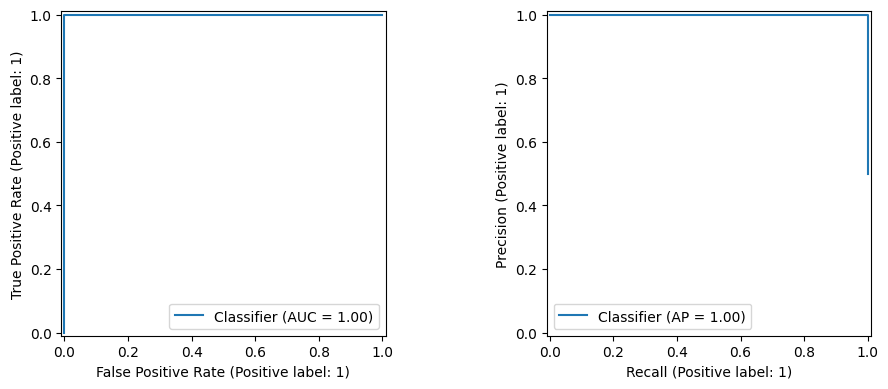

In [4]:
vp = model.predict_proba(val[FEATURES])[:,1]
baseline_p = np.full(len(val),train[TARGET].mean())
train_p = model.predict_proba(train[FEATURES])[:,1]
display(pd.DataFrame({
    'NB_train': scores(train[TARGET],train_p),
    'NB_validation': scores(val[TARGET],vp),
    'Prior_only_validation': scores(val[TARGET],baseline_p)
}).T[['accuracy','log_loss']])
display(pd.DataFrame({'prior_only':scores(val[TARGET],baseline_p),
                      'NB_at_0.5':scores(val[TARGET],vp)}).T)
thresholds = threshold_table(val[TARGET],vp)
display(thresholds)
threshold = choose_threshold(thresholds)
assert threshold is not None, '预设规则无可行阈值：停止并报告，不得打开test。'
print('validation-selected threshold:',threshold)
thresholds.to_csv(OUT/'B-thresholds.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(10,4))
RocCurveDisplay.from_predictions(val[TARGET],vp,ax=axes[0])
PrecisionRecallDisplay.from_predictions(val[TARGET],vp,ax=axes[1])
fig.tight_layout(); fig.savefig(OUT/'B-ranking.png',dpi=150); plt.show()


## C 类内依赖、重复输入与概率
对应任务4.4与7.2；类内依赖的详细统计为选做。比较0/1/5份额外腰痛副本，原主模型和阈值保持不变。不要预设一次复制必然使评分变差。

,label,feature_a,feature_b,n,p_a,p_b,joint,product,difference
15,1,fever_ge_38,nausea,35,0.371429,0.371429,0.371429,0.137959,0.233469
20,1,nausea,lumbar_pain,35,0.371429,0.371429,0.371429,0.137959,0.233469
16,1,fever_ge_38,lumbar_pain,35,0.371429,0.371429,0.371429,0.137959,0.233469
13,0,urine_pushing,burning_urethra,37,0.351351,0.351351,0.351351,0.123448,0.227904
7,0,nausea,micturition_pain,37,0.135135,0.135135,0.135135,0.018262,0.116874
2,0,fever_ge_38,urine_pushing,37,0.675676,0.351351,0.351351,0.237400,0.113952
4,0,fever_ge_38,burning_urethra,37,0.675676,0.351351,0.351351,0.237400,0.113952
29,1,micturition_pain,burning_urethra,35,0.800000,0.485714,0.485714,0.388571,0.097143
25,1,lumbar_pain,micturition_pain,35,0.371429,0.800000,0.371429,0.297143,0.074286
22,1,nausea,micturition_pain,35,0.371429,0.800000,0.371429,0.297143,0.074286


extra copies= 0


,sample_id,y,original_p,duplicate_p,change
0,A081,0,0.010210,0.010210,0.0
1,A109,0,0.097602,0.097602,0.0
22,A018,1,0.986576,0.986576,0.0


extra copies= 1


,sample_id,y,original_p,duplicate_p,change
2,A034,1,0.685429,0.868474,0.183045
4,A094,1,0.874262,0.767972,0.106290
14,A102,1,0.921647,0.848470,0.073177


extra copies= 5


,sample_id,y,original_p,duplicate_p,change
4,A094,1,0.874262,0.145263,0.728999
0,A081,0,0.010210,0.724999,0.714789
3,A093,1,0.921647,0.223307,0.698340


,extra_copies,tn,fp,fn,tp,accuracy,sensitivity,specificity,precision,f1,roc_auc,average_precision,brier,log_loss,mean_max_probability
0,0,12,0,0,12,1.00,1.000000,1.000000,1.000,1.0,1.000000,1.000000,0.011766,0.087214,0.919603
1,1,12,0,0,12,1.00,1.000000,1.000000,1.000,1.0,1.000000,1.000000,0.008387,0.070425,0.934272
2,5,11,1,5,7,0.75,0.583333,0.916667,0.875,0.7,0.965278,0.965812,0.152888,0.385377,0.943939


,bin,n,mean_probability,observed_fraction
0,"(-0.001, 0.2]",12,0.089002,0.0
1,"(0.2, 0.4]",0,NaN,NaN
2,"(0.4, 0.6]",0,NaN,NaN
3,"(0.6, 0.8]",1,0.685429,1.0
4,"(0.8, 1.0]",11,0.950279,1.0


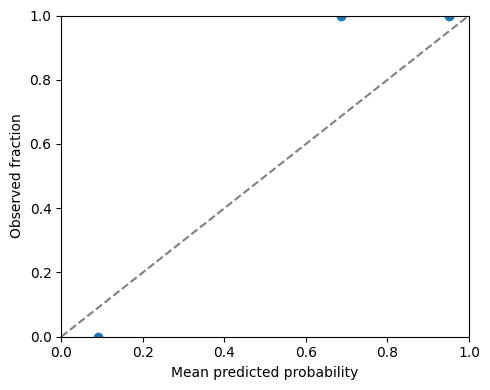

In [5]:
vp = model.predict_proba(val[FEATURES])[:,1]
dep = dependence(train).sort_values('difference',key=abs,ascending=False)
display(dep.head(10))
duplicates=[]
for copies in [0,1,5]:
    tx,vx=train[FEATURES].copy(),val[FEATURES].copy()
    for i in range(copies):
        tx[f'copy_{i}']=tx.lumbar_pain
        vx[f'copy_{i}']=vx.lumbar_pain
    dm=BernoulliNB(alpha=1,binarize=None).fit(tx,train[TARGET])
    dp=dm.predict_proba(vx)[:,1]
    duplicates.append(dict(extra_copies=copies,**scores(val[TARGET],dp),
                           mean_max_probability=np.maximum(dp,1-dp).mean()))
    changed=pd.DataFrame({'sample_id':val.sample_id,'y':val[TARGET],
                          'original_p':vp,'duplicate_p':dp,'change':abs(dp-vp)})
    print('extra copies=',copies); display(changed.sort_values('change',ascending=False).head(3))
display(pd.DataFrame(duplicates))
rel = reliability(val[TARGET],vp)
display(rel)
fig,ax=plt.subplots(figsize=(5,4))
ax.plot([0,1],[0,1],'--',color='gray')
ax.plot(rel.mean_probability,rel.observed_fraction,'o-')
ax.set(xlim=(0,1),ylim=(0,1),xlabel='Mean predicted probability',ylabel='Observed fraction')
fig.tight_layout(); fig.savefig(OUT/'C-reliability.png',dpi=150); plt.show()


## 冻结记录
先完成任务6的阈值选择，在任务7.3填写固定方案和日期，提交教师；获得释放后修改顶部两个开关并从头运行。原72条模型不重训。保存冻结文件的行为本身不能阻止事后修改；教师应保留首次提交。

In [9]:
freeze = dict(target=TARGET,features=FEATURES,alpha=1,fever_cutoff=38,
              training_ids=train.sample_id.tolist(),threshold=threshold,
              refit_train_plus_validation=False)
if FREEZE_CONFIRMED:
    (OUT/'frozen-protocol.json').write_text(json.dumps(freeze,indent=2),encoding='utf-8')
else:
    print('尚未确认冻结；D不运行。请先完成并提交冻结记录。')


尚未确认冻结；D不运行。请先完成并提交冻结记录。


## D 锁定测试、区间与压力测试
对应任务7.3。只有教师释放标签后运行；区间与压力测试属于选做输出。区间依赖二项独立抽样近似，原数据不支持直接推论临床总体。压力分位范围是给定模拟机制下的波动。

In [10]:
FREEZE_CONFIRMED = True      # 第 44 行：表示冻结记录已提交
OPEN_LOCKED_TEST = True      # 第 45 行：打开 D 单元的 test 分支
TRANSFER_FREEZE_CONFIRMED = False   # 第 46 行：别动，只有做选做 nephritis 才改

if OPEN_LOCKED_TEST:
    assert FREEZE_CONFIRMED, '必须先冻结主方案'
    test = pd.read_csv(BASE/'data/student/locked-test-features.csv').merge(
        pd.read_csv(BASE/'data/teacher/locked-test-labels.csv'),
        on='sample_id',validate='one_to_one',sort=False)
    assert not set(test.sample_id)&(set(train.sample_id)|set(val.sample_id))
    test_p=model.predict_proba(test[FEATURES])[:,1]
    test_scores=scores(test[TARGET],test_p,threshold)
    display(pd.Series(test_scores))
    intervals={'accuracy':wilson(test_scores['tn']+test_scores['tp'],len(test)),
               'sensitivity':wilson(test_scores['tp'],test_scores['tp']+test_scores['fn']),
               'specificity':wilson(test_scores['tn'],test_scores['tn']+test_scores['fp'])}
    print('Wilson95%',intervals)
    print('test profiles seen in train:',sum(tuple(x) in profiles_train for x in test[FEATURES].to_numpy()))
    stress_results=stress(model,test,test[TARGET],threshold)
    display(stress_results)
    stress_results.to_csv(OUT/'D-stress.csv',index=False)
else:
    print('测试关闭。完成A–C与冻结记录后，等待教师释放。')


tn                   12.000000
fp                    0.000000
fn                    0.000000
tp                   12.000000
accuracy              1.000000
sensitivity           1.000000
specificity           1.000000
precision             1.000000
f1                    1.000000
roc_auc               1.000000
average_precision     1.000000
brier                 0.012641
log_loss              0.074492
dtype: float64

Wilson95% {'accuracy': [0.8620237953250198, 1.0], 'sensitivity': [0.7575059933447592, 1.0], 'specificity': [0.7575059933447592, 1.0]}
test profiles seen in train: 24


,flip_rate,metric,mean,sd,q05,q95,repeats,seed
0,0.00,accuracy,1.000000,0.000000,1.000000,1.000000,1000,42
1,0.00,sensitivity,1.000000,0.000000,1.000000,1.000000,1000,42
2,0.00,specificity,1.000000,0.000000,1.000000,1.000000,1000,42
3,0.05,accuracy,0.956708,0.041968,0.875000,1.000000,1000,42
4,0.05,sensitivity,0.947417,0.064520,0.833333,1.000000,1000,42
5,0.05,specificity,0.966000,0.052700,0.833333,1.000000,1000,42
6,0.10,accuracy,0.909208,0.056409,0.791667,1.000000,1000,42
7,0.10,sensitivity,0.894167,0.083087,0.750000,1.000000,1000,42
8,0.10,specificity,0.924250,0.073669,0.750000,1.000000,1000,42
9,0.20,accuracy,0.810042,0.077212,0.666667,0.916667,1000,42


## E 选做 更换预测目标为 nephritis
保持完全相同的行划分。先完成validation与依赖检查，再提交第二份冻结记录。换标签不等于外部验证。

In [7]:
transfer_model=fit_model(train,'nephritis')
np_val=transfer_model.predict_proba(val[FEATURES])[:,1]
transfer_thresholds=threshold_table(val.nephritis,np_val)
display(transfer_thresholds)
transfer_threshold=choose_threshold(transfer_thresholds)
display(dependence(train,'nephritis').sort_values('difference',key=abs,ascending=False).head())
print('transfer validation threshold=',transfer_threshold)
if TRANSFER_FREEZE_CONFIRMED:
    assert transfer_threshold is not None
    (OUT/'transfer-frozen-protocol.json').write_text(json.dumps(
        dict(target='nephritis',features=FEATURES,alpha=1,threshold=transfer_threshold,
             training_ids=train.sample_id.tolist()),indent=2),encoding='utf-8')
if OPEN_TRANSFER_TEST:
    assert OPEN_LOCKED_TEST and FREEZE_CONFIRMED and TRANSFER_FREEZE_CONFIRMED
    transfer_scores=scores(test.nephritis,transfer_model.predict_proba(test[FEATURES])[:,1],transfer_threshold)
    display(pd.Series(transfer_scores))
    print('阳性分母=',int(test.nephritis.sum()),'阴性分母=',int((test.nephritis==0).sum()))
else:
    print('迁移测试关闭；先冻结并提交第二份方案。')


,threshold,tn,fp,fn,tp,accuracy,sensitivity,specificity,precision,f1,roc_auc,average_precision,brier,log_loss
0,0.05,11,0,0,13,1.000000,1.000000,1.0,1.0,1.000000,1.0,1.0,0.001516,0.021418
1,0.10,11,0,0,13,1.000000,1.000000,1.0,1.0,1.000000,1.0,1.0,0.001516,0.021418
2,0.20,11,0,0,13,1.000000,1.000000,1.0,1.0,1.000000,1.0,1.0,0.001516,0.021418
3,0.30,11,0,0,13,1.000000,1.000000,1.0,1.0,1.000000,1.0,1.0,0.001516,0.021418
4,0.50,11,0,0,13,1.000000,1.000000,1.0,1.0,1.000000,1.0,1.0,0.001516,0.021418
5,0.70,11,0,0,13,1.000000,1.000000,1.0,1.0,1.000000,1.0,1.0,0.001516,0.021418
6,0.80,11,0,0,13,1.000000,1.000000,1.0,1.0,1.000000,1.0,1.0,0.001516,0.021418
7,0.90,11,0,0,13,1.000000,1.000000,1.0,1.0,1.000000,1.0,1.0,0.001516,0.021418
8,0.95,11,0,5,8,0.791667,0.615385,1.0,1.0,0.761905,1.0,1.0,0.001516,0.021418


,label,feature_a,feature_b,n,p_a,p_b,joint,product,difference
22,1,nausea,micturition_pain,31,0.580645,0.580645,0.580645,0.337149,0.243496
14,0,micturition_pain,burning_urethra,41,0.365854,0.292683,0.292683,0.107079,0.185604
29,1,micturition_pain,burning_urethra,31,0.580645,0.580645,0.161290,0.337149,-0.175858
23,1,nausea,burning_urethra,31,0.580645,0.580645,0.161290,0.337149,-0.175858
12,0,urine_pushing,micturition_pain,41,0.536585,0.365854,0.365854,0.196312,0.169542


transfer validation threshold= 0.5
迁移测试关闭；先冻结并提交第二份方案。


## 学习综合
完成任务7.4的一页说明或流程图，用自己的计算解释七个核心知识点。引用输出时写明数据部分、阈值和分母。不要求审批结论或CERB。结果和图保存在项目根目录 `.tmp/naive-bayes/student-results/`，不要提交这些缓存。